# 82514 · Sesión S15 — El estado de la articulación: autovalores, controlabilidad, polos y observador

**Bloque 5** · lunes 9 de noviembre de 2026 · 2 h · IQS Universitat Ramon Llull

La tercera forma del modelo, pendiente desde S13: el hombro, mandado en tensión, como ẋ = A·x + B·u; autovalores, controlabilidad, observabilidad, polos con el techo de 24 V y un observador.

| | |
|---|---|
| **En clase** | Secciones 1 y 2, sin deteneros; la 3, con el ejercicio de clase. Al acabar, abrid el S15b y ejecutad su primera celda. |
| **En casa** | Sección 4 y ejercicios 1 a 3. Las soluciones están al final. |
| **Entrega** | No se sube. |

Cada paso tiene tres celdas: **▶ Parámetros**, lo único que se cambia; **⚙ Cálculo**, que no hace falta tocar; y **✔ Resultado**, lo que sale. En las celdas **✎ Completad**, el hueco está marcado con `None`.

---

In [1]:
# @title ⚙ Instalación · ejecutad esta celda primero
# Ejecutar una sola vez. En Colab tarda unos segundos.
import importlib, subprocess, sys

def asegurar(mods):
    faltan = []
    for pip_name, import_name in mods:
        try:
            importlib.import_module(import_name)
        except ImportError:
            faltan.append(pip_name)
    if faltan:
        print('Instalando:', ' '.join(faltan))
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + faltan, check=False)
    else:
        print('Todo instalado ya.')

asegurar([('numpy', 'numpy'), ('scipy', 'scipy'), ('matplotlib', 'matplotlib'), ('control==0.10.2', 'control')])

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import control as ct

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (9, 3.4)
plt.rcParams['axes.grid'] = True
IQS_AZUL, IQS_VERDE = '#1B2A80', '#1FA355'
GRIS, AMBAR, NAVY, ROJO = '#8A8FA8', '#B9770E', '#2E3FA3', '#C0392B'
COMA = FuncFormatter(lambda v, p: f'{v:g}'.replace('.', ','))   # ejes con coma decimal

def ejes(*axs):
    for ax in axs:
        ax.xaxis.set_major_formatter(COMA); ax.yaxis.set_major_formatter(COMA)

def coma(x, fmt='.3g'):
    """Un número con coma decimal, para los rótulos de las figuras."""
    return format(x, fmt).replace('.', ',')

print('python-control', ct.__version__, '- listo.')
if ct.__version__ != '0.10.2':
    print('AVISO: este cuaderno se probó con python-control 0.10.2. Ejecuta  !pip install -q control==0.10.2  y reinicia el entorno.')

Instalando: control==0.10.2
python-control 0.10.2 - listo.


## 1. La tercera forma del modelo

*En clase, sin deteneros · diapositivas 43 y 44*

El hombro de S13 (q̈ + 4,630·q̇ = 1,852·V) con estado x = (q, q̇): ẋ = A·x + B·V, y el encoder mide y = C·x = q. Mirad que los autovalores de A son los polos de S13.

In [2]:
# @title ▶ Parámetros · cambiad solo esto
# el hombro estirado (cuaderno S13a): constante de tiempo [s]
TM = 0.216  # @param {type:"number"}
# ganancia [rad/s por voltio]
K0 = 0.4  # @param {type:"number"}

In [3]:
# @title ⚙ Cálculo · no hace falta tocarlo
a, bv = 1/TM, K0/TM                  # 4.630 1/s y 1.852 rad/s² por voltio, como en el cuaderno S14
A = np.array([[0, 1], [0, -a]])      # x = (q, q')
B = np.array([[0], [bv]])            # u = V
C = np.array([[1, 0]])               # el encoder mide q
art = ct.ss(A, B, C, 0)              # la articulación, en estado (el 0: nada pasa directo de V a y)
P13 = ct.tf([K0], [TM, 1, 0])        # la función de transferencia de S13
P_art = ct.ss2tf(art)                # la que sale del estado
autov, polos13 = np.linalg.eigvals(A), ct.poles(P13)

w, Vp = np.linalg.eig(A)             # autovalores y, en las columnas de Vp, los vectores propios
vec = [v/v[np.argmax(np.abs(v))] for v in Vp.T]    # escalados: la mayor componente, 1
Av = [A @ v for v in vec]            # A solo los estira: A·v = autovalor·v

otro = ct.tf2ss(P13)                 # otro estado para la misma función de transferencia
autov_otro = np.linalg.eigvals(otro.A)

In [4]:
# @title ✔ Resultado
print('A =\n', A)
print('B =', B.ravel(), '   C =', C.ravel())
print('autovalores de A:', autov)
print(f'polos de S13, {K0}/(s·({TM} s + 1)):', polos13)
print('ss2tf:', P_art)
for lam, v, Avi in zip(w, vec, Av):
    print(f'autovalor {lam:7.3f}   vector propio {np.round(v, 3)}   A·v = {np.round(Avi, 3)}')
print()
print('tf2ss: A =\n', np.round(otro.A, 3) + 0.0)
print('       B =', otro.B.ravel(), '   C =', np.round(otro.C.ravel(), 3))
print('       autovalores:', autov_otro, ' <- los mismos')

A =
 [[ 0.      1.    ]
 [ 0.     -4.6296]]
B = [0.     1.8519]    C = [1 0]
autovalores de A: [ 0.     -4.6296]
polos de S13, 0.4/(s·(0.216 s + 1)): [-4.6296+0.j  0.    +0.j]
ss2tf: <TransferFunction>: sys[2]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

     1.852
  ------------
  s^2 + 4.63 s
autovalor   0.000   vector propio [1. 0.]   A·v = [0. 0.]
autovalor  -4.630   vector propio [-0.216  1.   ]   A·v = [ 1.   -4.63]

tf2ss: A =
 [[-4.63  0.  ]
 [ 1.    0.  ]]
       B = [1. 0.]    C = [0.    1.852]
       autovalores: [ 0.     -4.6296]  <- los mismos


**Qué tiene que salir:** autovalores 0 y −4,63, los polos de S13; `ss2tf`, 1,852/(s² + 4,63·s); el 0, con la dirección (1; 0), es el integrador; `tf2ss`, otras matrices y los mismos autovalores.

## 2. Controlabilidad y observabilidad

*En clase, sin deteneros · diapositivas 45 y 48*

`ct.ctrb(A, B)` = [B, A·B] y `ct.obsv(A, C)` = [C; C·A]: controlable u observable si el rango es n. Mirad el rango con el encoder, con solo la velocidad (C = [0, 1]) y con dos articulaciones mandadas con una sola tensión (n = 4).

In [5]:
# @title ⚙ Cálculo · no hace falta tocarlo
n = A.shape[0]                               # el orden: 2
Co = ct.ctrb(A, B)                           # [B, A·B]
r_Co, det_Co = np.linalg.matrix_rank(Co), np.linalg.det(Co)
Ob = ct.obsv(A, C)                           # [C; C·A] con el encoder
Ov = ct.obsv(A, np.array([[0, 1]]))          # con solo un tacómetro: mide q'
r_Ob, r_Ov = np.linalg.matrix_rank(Ob), np.linalg.matrix_rank(Ov)

Z = np.zeros((2, 2))
A_juntas = np.block([[A, Z], [Z, A]])                     # dos articulaciones iguales: n = 4
B_una = np.vstack([B, B])                                 # una sola tensión para las dos
B_dos = np.block([[B, np.zeros((2, 1))], [np.zeros((2, 1)), B]])   # una tensión para cada una
r_una = np.linalg.matrix_rank(ct.ctrb(A_juntas, B_una))
r_dos = np.linalg.matrix_rank(ct.ctrb(A_juntas, B_dos))

In [6]:
# @title ✔ Resultado
print('[B, A·B] =\n', Co)
print(f'rango {r_Co} de n = {n}, determinante {det_Co:.3f}  ->  ' + ('controlable' if r_Co == n else 'no controlable'))
print()
print('[C; C·A] con el encoder =\n', Ob, '\n  rango', r_Ob)
print('[C; C·A] con solo la velocidad =\n', Ov, '\n  rango', r_Ov)
print()
print('dos articulaciones, con una tensión:  rango', r_una, 'de 4')
print('dos articulaciones, con dos tensiones: rango', r_dos, 'de 4')

[B, A·B] =
 [[ 0.      1.8519]
 [ 1.8519 -8.5734]]
rango 2 de n = 2, determinante -3.429  ->  controlable

[C; C·A] con el encoder =
 [[1. 0.]
 [0. 1.]] 
  rango 2
[C; C·A] con solo la velocidad =
 [[ 0.      1.    ]
 [ 0.     -4.6296]] 
  rango 1

dos articulaciones, con una tensión:  rango 2 de 4
dos articulaciones, con dos tensiones: rango 4 de 4


**Qué tiene que salir:** [B, A·B] con filas (0; 1,852) y (1,852; −8,573), rango 2: controlable. Con el encoder, rango 2; con solo la velocidad, 1. Dos articulaciones con una tensión, rango 2 de 4: su diferencia no la mueve nadie; con dos tensiones, 4.

## 3. Colocar los polos

*En clase · diapositivas 46 y 47, y el ejercicio de clase*

`ct.place(A, B, polos)` da k = (k₁, k₂) para V = k₁·(q_ref − q) − k₂·q̇: el PD de S14, con 1,852·k₁ = ω_n². Al arrancar un salto de X rad, V(0) = k₁·X, y el motor da como mucho 24 V.

In [7]:
# @title ▶ Parámetros · cambiad solo esto
# polos pedidos: los dos polos del par, con su conjugado [rad/s]
POLOS = [-4+3j, -4-3j]  # @param {type:"raw"}
# techo de tensión del motor [V]
VMAX = 24  # @param {type:"number"}

In [8]:
# @title ⚙ Cálculo · no hace falta tocarlo
def nombre(par):
    '''Los dos polos del par como texto: -4 ± 3j si son complejos; -6 y -7.4 si son reales.'''
    p1, p2 = complex(par[0]), complex(par[-1])
    return f'{p1.real:g} ± {abs(p1.imag):g}j' if p1.imag != 0 else f'{p1.real:g} y {p2.real:g}'

k = ct.place(A, B, POLOS)                    # una fila de 1 x 2: (k1, k2)
wn = np.sqrt(np.real(np.prod(POLOS)))        # s² + 2·zeta·wn·s + wn²: wn² = p1·p2
zeta = -np.real(np.sum(POLOS))/(2*wn)        # y 2·zeta·wn = -(p1 + p2); con -4 ± 3j, 5 y 0.8
k1_s14, k2_s14 = wn**2/bv, (2*zeta*wn - a)/bv   # las fórmulas de Kp y Kd del cuaderno S14
wn_techo = np.sqrt(bv*VMAX)                  # con 1 rad, k1 = wn²/bv no puede pasar de VMAX

In [9]:
# @title ✔ Resultado
print(f'place({nombre(POLOS)}):', k, '  forma', k.shape, '-> el PD de S14')
print(f'con las fórmulas de S14: k1 = wn²/bv = {k1_s14:.2f}   k2 = (2·zeta·wn - a)/bv = {k2_s14:.2f}')
print(f'techo con 1 rad: wn <= sqrt(bv·{VMAX}) = {wn_techo:.2f} rad/s')

place(-4 ± 3j): [[13.5   1.82]]   forma (1, 2) -> el PD de S14
con las fórmulas de S14: k1 = wn²/bv = 13.50   k2 = (2·zeta·wn - a)/bv = 1.82
techo con 1 rad: wn <= sqrt(bv·24) = 6.67 rad/s


**Qué tiene que salir:** k = (13,5; 1,82), lo mismo que las fórmulas de S14. Con 1 rad y 24 V, ω_n ≤ 6,67 rad/s: el medio disco de la diapositiva 47.

**El techo, simulado.** `respuesta(k, r, vmax)` integra el salto con la tensión recortada a ±vmax (Runge-Kutta, paso de 0,1 ms); `metricas` da M_p y t_s con la banda del 2 %. Mirad la tensión que pide cada par y cuánto tiempo satura.

In [10]:
# @title ▶ Parámetros · cambiad solo esto
# pares de polos de la tabla, cada uno con su conjugado [rad/s]
POLOS_TABLA = [-4+3j, -5+5j, -20+5j]  # @param {type:"raw"}
# salto de la referencia [rad]
R_SALTO = 1.0  # @param {type:"number"}

In [11]:
# @title ⚙ Cálculo · no hace falta tocarlo
def respuesta(k, r=1.0, vmax=None, T=4.0, h=1e-4):
    '''Salto de r rad sin gravedad con V = k1·(r - q) - k2·q' y, si se da, el techo ±vmax. Devuelve t, q y V.'''
    k1, k2 = np.ravel(k)                     # admite la k de ct.place tal cual (una fila de 1 x 2)
    n = int(round(T/h)); q = w = 0.0
    t = np.arange(n + 1)*h; Q = np.zeros(n + 1); Vv = np.zeros(n + 1)
    def f(q_, w_):
        V = k1*(r - q_) - k2*w_
        V = V if vmax is None else min(max(V, -vmax), vmax)
        return w_, -a*w_ + bv*V, V
    for i in range(n):                       # Runge-Kutta de cuarto orden, paso h
        s1 = f(q, w); s2 = f(q + h/2*s1[0], w + h/2*s1[1])
        s3 = f(q + h/2*s2[0], w + h/2*s2[1]); s4 = f(q + h*s3[0], w + h*s3[1])
        Vv[i] = s1[2]
        q += h/6*(s1[0] + 2*s2[0] + 2*s3[0] + s4[0]); w += h/6*(s1[1] + 2*s2[1] + 2*s3[1] + s4[1])
        Q[i + 1] = q
    Vv[-1] = f(q, w)[2]
    return t, Q, Vv

def metricas(t, Q, r):
    '''Sobreoscilación [%] y tiempo de establecimiento [s] con la banda del 2 % del salto.'''
    fuera = np.nonzero(np.abs(Q - r) > 0.02*r)[0]
    return round(float(max(0.0, (Q.max() - r)/r*100)), 2), round(float(t[fuera[-1] + 1]), 3)

tabla, curvas = [], {}                       # una fila y unas curvas por cada par de polos
for p in POLOS_TABLA:
    kp = ct.place(A, B, [p, p.conjugate()])
    t, q_lin, V_lin = respuesta(kp, r=R_SALTO)               # sin techo
    t, q_sat, V_sat = respuesta(kp, r=R_SALTO, vmax=VMAX)    # con el techo
    sat = np.sum(np.abs(V_sat) >= VMAX - 1e-9)*(t[1] - t[0])  # tiempo saturado [s]
    curvas[nombre([p, p.conjugate()])] = (t, q_lin, q_sat, V_sat)
    tabla.append((nombre([p, p.conjugate()]), kp[0, 0], kp[0, 1], np.abs(V_lin).max(),
                  *metricas(t, q_lin, R_SALTO), *metricas(t, q_sat, R_SALTO), sat))

     polos      k1     k2  pide [V] | sin techo: Mp [%] ts [s] | con 24 V: Mp [%] ts [s] saturado [s]
   -4 ± 3j    13.5   1.82      13.5 |              1.52  0.751 |             1.52  0.751        0.000
   -5 ± 5j    27.0   2.90      27.0 |              4.32  0.843 |             4.32  0.845        0.022
  -20 ± 5j   229.5  19.10     229.5 |              0.00  0.267 |             0.00  0.369        0.164


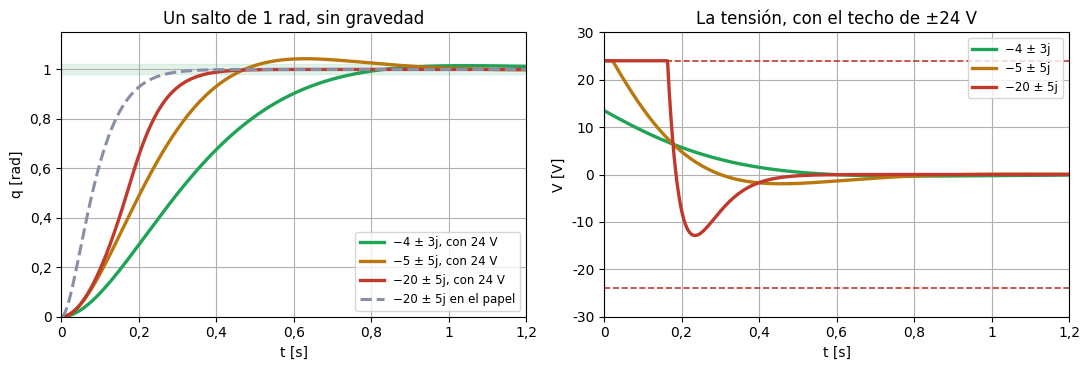

In [12]:
# @title ✔ Resultado
print(f"{'polos':>10} {'k1':>7} {'k2':>6} {'pide [V]':>9} | {'sin techo: Mp [%]':>17} {'ts [s]':>6} | "
      f"{f'con {VMAX} V: Mp [%]':>16} {'ts [s]':>6} {'saturado [s]':>12}")
for nom, k1, k2, pide, mp_l, ts_l, mp_s, ts_s, sat in tabla:
    print(f'{nom:>10} {k1:7.1f} {k2:6.2f} {pide:9.1f} | {mp_l:17.2f} {ts_l:6.3f} | {mp_s:16.2f} {ts_s:6.3f} {sat:12.3f}')

cols = [IQS_VERDE, AMBAR, ROJO, NAVY, IQS_AZUL]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for i, (nom, (t, q_lin, q_sat, V_sat)) in enumerate(curvas.items()):
    a1.plot(t, q_sat, color=cols[i % len(cols)], lw=2.4, label=nom.replace('-', '−') + f', con {VMAX} V')
    a2.plot(t, V_sat, color=cols[i % len(cols)], lw=2.4, label=nom.replace('-', '−'))
nom, (t, q_lin, _, _) = list(curvas.items())[-1]          # el último par, sin techo
a1.plot(t, q_lin, color=GRIS, lw=2.2, ls='--', label=nom.replace('-', '−') + ' en el papel')
a1.axhspan(0.98*R_SALTO, 1.02*R_SALTO, color=IQS_VERDE, alpha=0.12)
a1.set_xlim(0, 1.2); a1.set_ylim(0, 1.15*R_SALTO); a1.set_xlabel('t [s]'); a1.set_ylabel('q [rad]')
a1.set_title(f'Un salto de {coma(R_SALTO, "g")} rad, sin gravedad'); a1.legend(loc='lower right', fontsize=8.5)
a2.axhline(VMAX, color=ROJO, lw=1.2, ls='--'); a2.axhline(-VMAX, color=ROJO, lw=1.2, ls='--')
a2.set_xlim(0, 1.2); a2.set_ylim(-1.25*VMAX, 1.25*VMAX); a2.set_xlabel('t [s]'); a2.set_ylabel('V [V]')
a2.set_title(f'La tensión, con el techo de ±{VMAX} V'); a2.legend(loc='upper right', fontsize=8.5)
ejes(a1, a2); plt.tight_layout(); plt.show()

**Qué tiene que salir:** −4 ± 3j pide 13,5 V: cabe, con el 1,52 % y 0,751 s de S14. −5 ± 5j, k = (27; 2,90), pide 27 V y satura 22 ms. −20 ± 5j pide 230 V: 0,267 s en el papel y 0,369 s con 24 V.

### Ejercicio de clase

- **Objetivo:** los polos −σ ± σ·j (ζ = 0,707) más rápidos sin pasar de 24 V, con 1 rad y con 0,506 rad (los 29° de S12).
- **Tocáis:** `SALTOS`.
- **Completáis:** `sigma_max(X)`. Pista: con esos polos, ω_n² = 2σ², y V(0) = k₁ por el salto.
- **Mirad:** k, M_p y t_s; se pone en común.

In [13]:
# @title ▶ Parámetros · cambiad solo esto
# saltos [rad]: 1 rad y el giro de 29° de S12
SALTOS = (1.0, 0.506)  # @param {type:"raw"}

In [14]:
# @title ✎ Completad · el hueco está marcado con None
def sigma_max(X):
    '''sigma de los polos -sigma ± sigma·j que, con un salto de X rad, piden justo VMAX voltios al arrancar.'''
    return np.sqrt(bv*VMAX/(2*X))  # ← completad: de k1·X = VMAX, con k1 = 2·sigma²/bv

In [15]:
# @title ⚙ Cálculo · no hace falta tocarlo
ej_clase = []                                # (X, sigma, k, V(0), Mp, ts) de cada salto
for X in SALTOS:
    sig = sigma_max(X)
    if sig is None:                          # el hueco sigue vacío
        ej_clase = None
        break
    k_ej = np.ravel(ct.place(A, B, [-sig + sig*1j, -sig - sig*1j]))
    t, q, V = respuesta(k_ej, r=X, vmax=VMAX)
    ej_clase.append((X, sig, k_ej, k_ej[0]*X, *metricas(t, q, X)))

In [16]:
# @title ✔ Resultado
if ej_clase is None:
    print('Pendiente: completad sigma_max en la celda ✎')
else:
    print(f"{'salto [rad]':>11} {'sigma':>7} {'k1':>6} {'k2':>6} {'V(0) [V]':>9} {'Mp [%]':>7} {'ts [s]':>7}")
    for X, sig, k_ej, V0, mp, ts in ej_clase:
        print(f'{X:11.3f} {sig:7.3f} {k_ej[0]:6.1f} {k_ej[1]:6.2f} {V0:9.1f} {mp:7.2f} {ts:7.3f}')

salto [rad]   sigma     k1     k2  V(0) [V]  Mp [%]  ts [s]
      1.000   4.714   24.0   2.59      24.0    4.32   0.894
      0.506   6.627   47.4   4.66      24.0    4.32   0.636


## 4. El observador

*En casa · diapositiva 49*

Una copia del modelo recibe la misma tensión y se corrige con lo que se separa del encoder: x̂̇ = A·x̂ + B·V + ℓ·(q − q̂), con ℓ = place(Aᵀ, Cᵀ, polos)ᵀ. Mirad que el conjunto conserva los polos del control y los del observador.

In [17]:
# @title ▶ Parámetros · cambiad solo esto
# polos del observador, más rápidos que los del control [1/s]
POLOS_OBS = [-20, -25]  # @param {type:"raw"}
# polos del control, el PD de S14 [rad/s]
POLOS_CTRL = [-4+3j, -4-3j]  # @param {type:"raw"}

In [18]:
# @title ⚙ Cálculo · no hace falta tocarlo
ell = ct.place(A.T, C.T, POLOS_OBS).T         # la ganancia del observador, una columna
eig_err = np.linalg.eigvals(A - ell @ C)       # los polos del error de estimación
k_pd = ct.place(A, B, POLOS_CTRL)              # el control
# el conjunto (x, x_gorro) con V = -k·x_gorro: x' = A·x - B·k·x_gorro y x_gorro' = ell·C·x + (A - B·k - ell·C)·x_gorro
A_conj = np.block([[A, -B @ k_pd], [ell @ C, A - B @ k_pd - ell @ C]])
polos_conj = np.linalg.eigvals(A_conj)

In [19]:
# @title ✔ Resultado
print('ell =', ell.ravel(), '   autovalores de A - ell·C:', eig_err)
print('polos del conjunto:', np.round(polos_conj, 3))

ell = [ 40.3704 313.1001]    autovalores de A - ell·C: [-25. -20.]
polos del conjunto: [-25.+0.j -20.+0.j  -4.+3.j  -4.-3.j]


**Qué tiene que salir:** ℓ = (40,4; 313,1); el conjunto tiene los polos −20, −25 y −4 ± 3j.

**El brazo empujado.** Arranca en q = 0,2 rad con q̇ = 1 rad/s; el observador, que no lo sabe, en (0; 0). `ct.initial_response` simula el conjunto. En gris, el mismo brazo con el estado medido, V = −k·x.

In [20]:
# @title ▶ Parámetros · cambiad solo esto
# estado inicial del brazo: q [rad] y q' [rad/s]
X0_BRAZO = [0.2, 1.0]  # @param {type:"raw"}
# estado inicial del observador: q_gorro [rad] y q_gorro' [rad/s]
X0_OBS = [0.0, 0.0]  # @param {type:"raw"}
# duración del ensayo [s]
T_ENSAYO = 1.5  # @param {type:"number"}

In [21]:
# @title ⚙ Cálculo · no hace falta tocarlo
x0, xg0 = np.array(X0_BRAZO, dtype=float), np.array(X0_OBS, dtype=float)
t_obs = np.linspace(0, T_ENSAYO, int(round(T_ENSAYO/1e-4)) + 1)             # cada 0.1 ms
X_conj = ct.initial_response(ct.ss(A_conj, np.zeros((4, 1)), np.eye(4), 0), t_obs, X0=np.r_[x0, xg0]).states
X_med = ct.initial_response(ct.ss(A - B @ k_pd, np.zeros((2, 1)), np.eye(2), 0), t_obs, X0=x0).states
err = np.linalg.norm(X_conj[0:2] - X_conj[2:4], axis=0)   # el tamaño del error de estimación
t2 = t_obs[np.nonzero(err >= 0.02*err[0])[0][-1] + 1] if err[0] > 0 else 0.0   # baja del 2 % de err[0]
dq_max = np.degrees(np.abs(X_conj[0] - X_med[0]).max())   # q con el estado estimado frente al medido [°]

el error de estimación baja del 2 % de su valor inicial en 0.286 s
q con el estado estimado frente a q con el medido: 0.35° como mucho


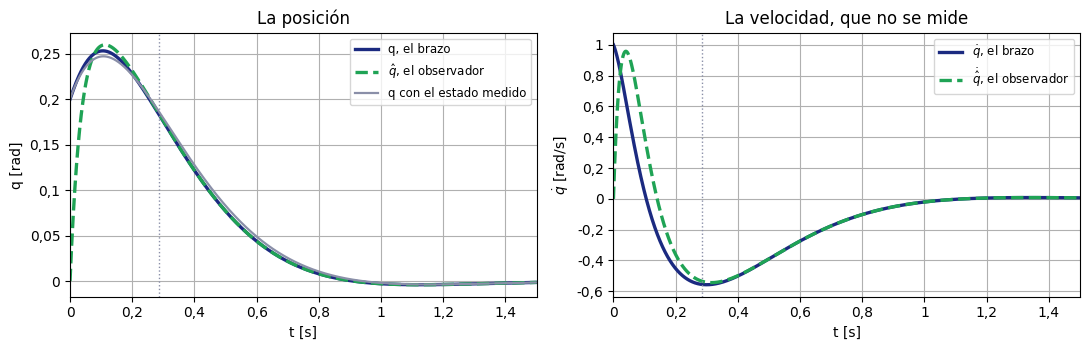

In [22]:
# @title ✔ Resultado
print(f'el error de estimación baja del 2 % de su valor inicial en {t2:.3f} s')
print(f'q con el estado estimado frente a q con el medido: {dq_max:.2f}° como mucho')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(t_obs, X_conj[0], color=IQS_AZUL, lw=2.4, label='q, el brazo')
a1.plot(t_obs, X_conj[2], color=IQS_VERDE, lw=2.4, ls='--', label=r'$\hat{q}$, el observador')
a1.plot(t_obs, X_med[0], color=GRIS, lw=1.6, label='q con el estado medido')
a2.plot(t_obs, X_conj[1], color=IQS_AZUL, lw=2.4, label=r'$\dot{q}$, el brazo')
a2.plot(t_obs, X_conj[3], color=IQS_VERDE, lw=2.4, ls='--', label=r'$\dot{\hat{q}}$, el observador')
for ax, yl, ti in ((a1, 'q [rad]', 'La posición'), (a2, r'$\dot{q}$ [rad/s]', 'La velocidad, que no se mide')):
    ax.axvline(t2, color=GRIS, lw=1, ls=':'); ax.set_xlim(0, T_ENSAYO); ax.set_xlabel('t [s]'); ax.set_ylabel(yl)
    ax.set_title(ti); ax.legend(loc='upper right', fontsize=8.5)
ejes(a1, a2); plt.tight_layout(); plt.show()

**Qué tiene que salir:** el error de estimación baja del 2 % en 0,286 s, y la posición se separa como mucho 0,35° de la que da el estado medido.

### Ejercicio 1 (en casa)

La velocidad como salida: con C = [0, 1], un tacómetro, ¿qué da `ct.ss2tf`? Simplificadla con `ct.minreal` y comparadla con el primer orden de S13. ¿Qué rango de observabilidad sale y dónde ha ido el integrador?

In [23]:
# @title ▶ Parámetros · cambiad solo esto
# lo que mide el sensor: [[0, 1]] es solo la velocidad, un tacómetro
C_TAC = [[0, 1]]  # @param {type:"raw"}

In [ ]:
# @title ⚙ Cálculo · no hace falta tocarlo
C1 = np.array(C_TAC)
P_tac = ct.ss2tf(ct.ss(A, B, C1, 0))                 # la función de transferencia vista desde el tacómetro
P_tac_min = ct.minreal(P_tac, verbose=False)         # sin los polos y ceros que se cancelan
r_tac = np.linalg.matrix_rank(ct.obsv(A, C1))

In [ ]:
# @title ✔ Resultado
print('ss2tf:', P_tac)
print('minreal:', P_tac_min)
print('rango de observabilidad:', r_tac, 'de', n, '   autovalores de A:', autov)

### Ejercicio 2 (en casa)

El brazo plegado: τ_m = 0,1264 s (cuaderno S13a), A = [[0, 1], [0, −7,911]] y B = (0; 3,165). ¿Dónde van los polos con la k del brazo estirado, (13,5; 1,82)? ¿Qué k los devuelve a −4 ± 3j?

In [ ]:
# @title ▶ Parámetros · cambiad solo esto
# constante de tiempo con el codo plegado (cuaderno S13a) [s]
TM_PLEG = 0.1264  # @param {type:"number"}
# polos del diseño [rad/s]
POLOS_PLEG = [-4+3j, -4-3j]  # @param {type:"raw"}

In [ ]:
# @title ⚙ Cálculo · no hace falta tocarlo
A_pleg = np.array([[0, 1], [0, -1/TM_PLEG]]); B_pleg = np.array([[0], [K0/TM_PLEG]])
k_est = ct.place(A, B, POLOS_PLEG)                   # la k del brazo estirado
lazo_pleg = A_pleg - B_pleg @ k_est                  # el brazo plegado con esa k
polos_pleg, pol_pleg = np.linalg.eigvals(lazo_pleg), np.poly(lazo_pleg)
k_pleg = ct.place(A_pleg, B_pleg, POLOS_PLEG)        # la k que devuelve los polos

In [ ]:
# @title ✔ Resultado
print('A_pleg =\n', A_pleg, '\nB_pleg =', B_pleg.ravel())
print('con la k del estirado', k_est.ravel(), ': polinomio', pol_pleg, '  polos', polos_pleg)
print('k para el plegado:', k_pleg.ravel())

### Ejercicio 3 (en casa)

Con el amplificador de corriente de S7 no hay contratensión: A = [[0, 1], [0, 0]] y B = (0; 3,704). ¿Es controlable? ¿Qué k da −4 ± 3j, y cuánta corriente pide un salto de 1 rad frente a sostener el brazo en horizontal (8,83 N·m) y a los 12 A con 24 V?

In [ ]:
# @title ▶ Parámetros · cambiad solo esto
# aceleración por amperio, G·K/M = 2.5/0.675 [rad/s² por amperio]
B_I = 3.704  # @param {type:"number"}
# polos del diseño [rad/s]
POLOS_I = [-4+3j, -4-3j]  # @param {type:"raw"}
# salto [rad]
SALTO_I = 1.0  # @param {type:"number"}
# par de la gravedad con el brazo horizontal [N·m]
PAR_G = 8.83  # @param {type:"number"}
# par por amperio en la articulación, G·K [N·m/A]
GK = 2.5  # @param {type:"number"}
# resistencia del motor [ohmios]
R_MOT = 2.0  # @param {type:"number"}

In [ ]:
# @title ⚙ Cálculo · no hace falta tocarlo
A_i = np.array([[0, 1], [0, 0]]); B_i = np.array([[0], [B_I]])
r_i = np.linalg.matrix_rank(ct.ctrb(A_i, B_i))
k_i = ct.place(A_i, B_i, POLOS_I)                    # [A/rad, A·s/rad]
i_salto = k_i[0, 0]*SALTO_I                          # la corriente al arrancar el salto [A]
i_g = PAR_G/GK                                       # la que sostiene el brazo en horizontal [A]
i_max = VMAX/R_MOT                                   # la del motor parado con VMAX voltios [A]

In [ ]:
# @title ✔ Resultado
print('rango de controlabilidad:', r_i, 'de 2')
print('k =', k_i.ravel(), ' [A/rad, A·s/rad]')
print(f'corriente al arrancar: {i_salto:.2f} A   sostener en horizontal: {i_g:.2f} A   con {VMAX} V: {i_max:.0f} A')

---

## Soluciones

**Ejercicio de clase.** `return np.sqrt(bv*VMAX/(2*X))`, de k₁·X = 2σ²·X/1,852 = 24. Con 1 rad: σ = 4,714, k = (24,0; 2,59), V(0) = 24 V, 4,32 % y 0,894 s. Con 0,506 rad: σ = 6,627, k = (47,4; 4,66), el mismo 4,32 % y 0,636 s. ζ = 0,707 fija la sobreoscilación; cuanto más corto el salto, más lejos van los polos: el límite es la tensión.

**Ejercicio 1.** 1,852·s/(s² + 4,63·s), que `minreal` deja en 1,852/(s + 4,63) = 0,4/(0,216·s + 1), el primer orden de S13. Rango 1: el integrador sigue en A (autovalores 0 y −4,63), pero el tacómetro no lo ve.

**Ejercicio 2.** Con la k del estirado, s² + 13,67·s + 42,7: polos −4,84 y −8,84 (ω_n = 6,54, ζ = 1,05; ya no oscila). k = (7,90; 0,03) los devuelve a −4 ± 3j. La k depende de la postura; el par calculado del S15b no.

**Ejercicio 3.** Rango 2: controlable. k = (6,75 A/rad; 2,16 A·s/rad), las fórmulas de S14 en corriente. El salto pide 6,75 A al arrancar, frente a 3,53 A para sostener el brazo y 12 A con 24 V. Sin contratensión, k₂ es el único amortiguador.

---

## Para llevarse de esta sesión

- **El estado es la memoria mínima** del sistema: en la articulación, q y q̇.
- **Los autovalores de A son los polos.** El estado no es único; los autovalores, sí.
- **Controlable y observable son dos rangos:** si [B, A·B] o [C; C·A] tiene rango n, sí.
- **Colocar los polos es diseñar el PD,** hasta donde deja la tensión: con 1 rad y 24 V, ω_n ≤ 6,67 rad/s.
- **El observador es el modelo corregido con la medida;** sus polos se colocan aparte.

*Cuaderno del curso 82514 Mecatrónica y Robótica · IQS Universitat Ramon Llull · curso 2026/27*

*© Guillermo Reyes Carmenaty · Publicado bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es): puedes usarlo, adaptarlo y redistribuirlo, incluso con fines comerciales, siempre que reconozcas la autoría.*